Outlier Detection & Visualization

In [1]:
# Import Libraries & Load Data
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
import numpy as np

In [2]:
# Load iris dataset
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


1) BOX & WHISKER PLOT

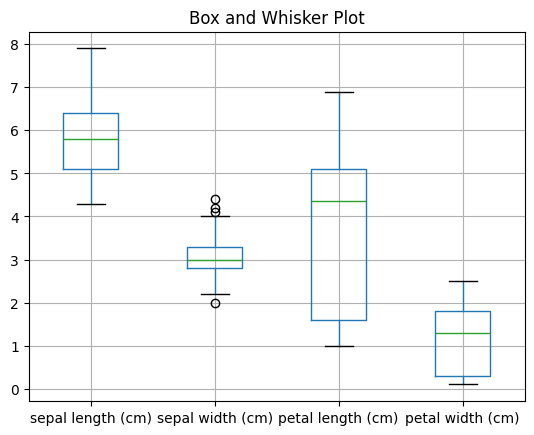

In [3]:
# Draw Box Plot
plt.figure()
df.boxplot()
plt.title("Box and Whisker Plot")
plt.show()

In [4]:
# Find Quartiles using .quantile()

In [5]:
# Calculate Quartiles
Q1 = df.quantile(0.25)   # First quartile (25%)
Q2 = df.quantile(0.50)   # Median (50%)
Q3 = df.quantile(0.75)   # Third quartile (75%)

print("Q1:\n", Q1)
print("\nQ2 (Median):\n", Q2)
print("\nQ3:\n", Q3)


Q1:
 sepal length (cm)    5.1
sepal width (cm)     2.8
petal length (cm)    1.6
petal width (cm)     0.3
Name: 0.25, dtype: float64

Q2 (Median):
 sepal length (cm)    5.80
sepal width (cm)     3.00
petal length (cm)    4.35
petal width (cm)     1.30
Name: 0.5, dtype: float64

Q3:
 sepal length (cm)    6.4
sepal width (cm)     3.3
petal length (cm)    5.1
petal width (cm)     1.8
Name: 0.75, dtype: float64


In [6]:
# Apply Tukey’s Method (IQR Method)

In [7]:
# Calculate Inter Quartile Range
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:\n", lower_bound)
print("\nUpper Bound:\n", upper_bound)


Lower Bound:
 sepal length (cm)    3.15
sepal width (cm)     2.05
petal length (cm)   -3.65
petal width (cm)    -1.95
dtype: float64

Upper Bound:
 sepal length (cm)     8.35
sepal width (cm)      4.05
petal length (cm)    10.35
petal width (cm)      4.05
dtype: float64


In [8]:
# Detect Outliers

In [9]:
# Check which values are outliers
outliers = ((df < lower_bound) | (df > upper_bound))

print("Number of outliers in each column:\n", outliers.sum())


Number of outliers in each column:
 sepal length (cm)    0
sepal width (cm)     4
petal length (cm)    0
petal width (cm)     0
dtype: int64


2) Z-SCORE METHOD

In [10]:
from scipy import stats

# Calculate Z-score
z_scores = np.abs(stats.zscore(df))

print(z_scores)

[[9.00681170e-01 1.01900435e+00 1.34022653e+00 1.31544430e+00]
 [1.14301691e+00 1.31979479e-01 1.34022653e+00 1.31544430e+00]
 [1.38535265e+00 3.28414053e-01 1.39706395e+00 1.31544430e+00]
 [1.50652052e+00 9.82172869e-02 1.28338910e+00 1.31544430e+00]
 [1.02184904e+00 1.24920112e+00 1.34022653e+00 1.31544430e+00]
 [5.37177559e-01 1.93979142e+00 1.16971425e+00 1.05217993e+00]
 [1.50652052e+00 7.88807586e-01 1.34022653e+00 1.18381211e+00]
 [1.02184904e+00 7.88807586e-01 1.28338910e+00 1.31544430e+00]
 [1.74885626e+00 3.62176246e-01 1.34022653e+00 1.31544430e+00]
 [1.14301691e+00 9.82172869e-02 1.28338910e+00 1.44707648e+00]
 [5.37177559e-01 1.47939788e+00 1.28338910e+00 1.31544430e+00]
 [1.26418478e+00 7.88807586e-01 1.22655167e+00 1.31544430e+00]
 [1.26418478e+00 1.31979479e-01 1.34022653e+00 1.44707648e+00]
 [1.87002413e+00 1.31979479e-01 1.51073881e+00 1.44707648e+00]
 [5.25060772e-02 2.16998818e+00 1.45390138e+00 1.31544430e+00]
 [1.73673948e-01 3.09077525e+00 1.28338910e+00 1.052179

In [11]:
# Detect Outliers using Z-score (Threshold = 3)
# Any Z-score > 3 is considered outlier
outliers_z = (z_scores > 3)

print("Outliers using Z-score:\n", outliers_z.sum(axis=0))


Outliers using Z-score:
 [0 1 0 0]


2b) STANDARDISATION

In [12]:
from sklearn.preprocessing import StandardScaler

# Create scaler object
scaler = StandardScaler()

# Standardize the data
df_standardized = scaler.fit_transform(df)

# Convert back to DataFrame
df_standardized = pd.DataFrame(df_standardized, columns=df.columns)

print(df_standardized.head())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0          -0.900681          1.019004          -1.340227         -1.315444
1          -1.143017         -0.131979          -1.340227         -1.315444
2          -1.385353          0.328414          -1.397064         -1.315444
3          -1.506521          0.098217          -1.283389         -1.315444
4          -1.021849          1.249201          -1.340227         -1.315444


3) SCATTER PLOT

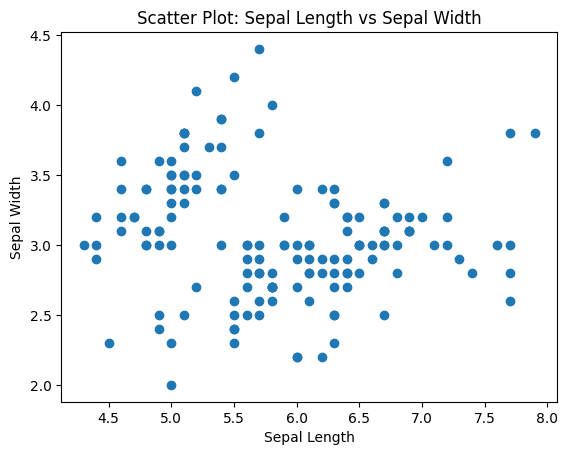

In [13]:
# Plot scatter graph between two features
plt.figure()
plt.scatter(df["sepal length (cm)"], df["sepal width (cm)"])
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Scatter Plot: Sepal Length vs Sepal Width")
plt.show()
